# Stranger Things — Character Analysis v2
## 修正说明
1. 堆积图紫色（中性）段加上比例标注
2. 情感分析改为**角色名周边8词窗口法**：只统计角色名前后8个词内的情感词，避免整体剧评干扰
   - `hopper died, this is terrible` → terrible 在 hopper 前2词内，会被捕捉（真实负面）
   - `best season ever` → best 距离角色名超过8词，不影响角色得分
   - `terrifying villain` → terrifying 在 vecna 周边，会被捕捉（但这是反派特质，属于正常）

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import re
import numpy as np

PATH = '/Users/cici/Desktop/PythonProject/'
combined = pd.read_csv(PATH + 'combined_data.csv')

def preprocess(text):
    if not isinstance(text, str): return ''
    return text.replace('&amp;', ' ').replace('&lt;', ' ').replace('&gt;', ' ')

combined['text_combined'] = (
    combined['title'].fillna('').apply(preprocess) + ' ' +
    combined['text'].fillna('').apply(preprocess)
)

print(f'Loaded {len(combined)} rows')
print(combined['source'].value_counts())

Loaded 8461 rows
source
IMDb      4461
Reddit    4000
Name: count, dtype: int64


In [7]:
# ── 角色别名词典 ───────────────────────────────────────────────
CHARACTER_DICT = {
    'Eleven':   [r'\beleven\b', r'\bjane\b'],
    'Mike':     [r'\bmike wheeler\b', r'\bmike\b'],
    'Will':     [r'\bwill byers\b',
                 r'\bwill\s+(byers|is|was|had|has|did|seemed|felt|went|got|said)\b',
                 r'\b(poor|missing|dead|alive|save|protect)\s+will\b'],
    'Dustin':   [r'\bdustin\b'],
    'Lucas':    [r'\blucas\b'],
    'Max':      [r'\bmax\b', r'\bmax mayfield\b'],
    'Hopper':   [r'\bhopper\b', r'\bjim hopper\b'],
    'Joyce':    [r'\bjoyce\b'],
    'Steve':    [r'\bsteve harrington\b', r'\bsteve\b'],
    'Billy':    [r'\bbilly hargrove\b', r'\bbilly\b'],
    'Robin':    [r'\brobin buckley\b', r'\brobin\b'],
    'Eddie':    [r'\beddie munson\b', r'\beddie\b'],
    'Vecna':    [r'\bvecna\b', r'\bhenry creel\b'],
    'Nancy':    [r'\bnancy wheeler\b', r'\bnancy\b'],
    'Jonathan': [r'\bjonathan byers\b', r'\bjonathan\b'],
}

# ── 角色专属情感词典（只描述人物特质的词）─────────────────────
# 不包含 'best/worst season' 这类剧集评价词
CHAR_POSITIVE = {
    'love','loved','like','liked','favorite','favourite','great','amazing',
    'awesome','brilliant','iconic','funny','witty','sweet','brave','kind',
    'strong','badass','cool','relatable','charming','charismatic','hilarious',
    'underrated','memorable','fantastic','incredible','wonderful','perfect',
    'exceptional','superb','outstanding','well written','well developed',
    'interesting','compelling','engaging','lovable','wholesome','genuine',
    'talented','impressive','captivating','touching','emotional','powerful'
}
CHAR_NEGATIVE = {
    'hate','hated','annoying','boring','useless','irrelevant','stupid',
    'unlikeable','weak','flat','terrible','awful','horrible','worst',
    'pathetic','disappointing','disappointed','forgettable','sidelined',
    'wasted','poor','bad','dull','forced','cliche','mediocre','overrated',
    'inconsistent','underdeveloped','cardboard','ridiculous','pointless',
    'irritating','unbearable','insufferable','whiny','selfish','toxic'
}
NEGATORS     = {'not','no','never','dont','doesnt','didnt','isnt','wasnt','arent','wont','cant','cannot'}
INTENSIFIERS = {'very','extremely','absolutely','totally','completely','really','so','such'}

def get_char_sentiment(text, char_patterns, window=8):
    """
    只统计角色名前后 window 个词内的情感词。
    'hopper is amazing' → 捕捉 amazing（距离1词）
    'best season ever, hopper died' → best 距离 hopper 超过8词，不影响得分
    """
    if not isinstance(text, str): return 0.0, 'neutral'
    text_lower = text.lower()
    words = re.findall(r'\b\w+\b', text_lower)

    # 找角色名在词列表中的位置
    char_positions = set()
    for i in range(len(words)):
        chunk = ' '.join(words[max(0, i-1):i+4])
        for p in char_patterns:
            if re.search(p, chunk):
                char_positions.add(i)

    if not char_positions:
        return 0.0, 'neutral'

    pos, neg = 0, 0
    for cp in char_positions:
        nearby = words[max(0, cp - window):min(len(words), cp + window + 1)]
        for i, word in enumerate(nearby):
            preceding = nearby[max(0, i-3):i]
            negated = any(n in preceding for n in NEGATORS)
            weight  = 1.5 if any(n in preceding for n in INTENSIFIERS) else 1.0
            if word in CHAR_POSITIVE:
                neg += weight if negated else 0
                pos += 0      if negated else weight
            elif word in CHAR_NEGATIVE:
                pos += weight * 0.5 if negated else 0
                neg += 0            if negated else weight

    total = pos + neg
    if total == 0: return 0.0, 'neutral'
    c = round((pos - neg) / total, 3)
    return c, ('positive' if c >= 0.2 else 'negative' if c <= -0.2 else 'neutral')

def detect_characters(text):
    if not isinstance(text, str): return []
    text_lower = text.lower()
    return list({char for char, patterns in CHARACTER_DICT.items()
                 if any(re.search(p, text_lower) for p in patterns)})

print('Running character detection...')
combined['characters'] = combined['text_combined'].apply(detect_characters)
print('Done.')

Running character detection...
Done.


In [8]:
# ── 计算角色情感（窗口法）────────────────────────────────────
print('Running character-level sentiment (window method)...')
rows = []
for _, row in combined.iterrows():
    for char in row['characters']:
        patterns = CHARACTER_DICT[char]
        score, label = get_char_sentiment(row['text_combined'], patterns)
        rows.append({
            'character':       char,
            'sentiment_score': score,
            'sentiment_label': label,
        })
char_df = pd.DataFrame(rows)

char_stats = char_df.groupby('character').agg(
    mentions      = ('sentiment_score', 'count'),
    avg_sentiment = ('sentiment_score', 'mean'),
    positive_rate = ('sentiment_label', lambda x: (x == 'positive').mean() * 100),
    negative_rate = ('sentiment_label', lambda x: (x == 'negative').mean() * 100),
    neutral_rate  = ('sentiment_label', lambda x: (x == 'neutral').mean() * 100),
).round(2)

char_stats = char_stats[
    char_stats['mentions'] >= 30
].sort_values('mentions', ascending=False)

print('=== Character Stats (window sentiment) ===')
print(char_stats)

Running character-level sentiment (window method)...
=== Character Stats (window sentiment) ===
           mentions  avg_sentiment  positive_rate  negative_rate  neutral_rate
character                                                                     
Eleven         1001           0.28          33.77           5.49         60.74
Hopper          755           0.21          25.83           4.77         69.40
Mike            565           0.27          32.04           4.78         63.19
Steve           553           0.35          40.51           5.06         54.43
Dustin          497           0.33          35.81           3.22         60.97
Nancy           467           0.22          27.19           4.71         68.09
Joyce           450           0.20          25.33           5.11         69.56
Max             387           0.32          36.69           4.39         58.91
Vecna           384           0.23          26.82           3.12         70.05
Will            307           0.14 

## 图1：角色情感分布堆积柱状图
修正：紫色（中性）段也显示比例

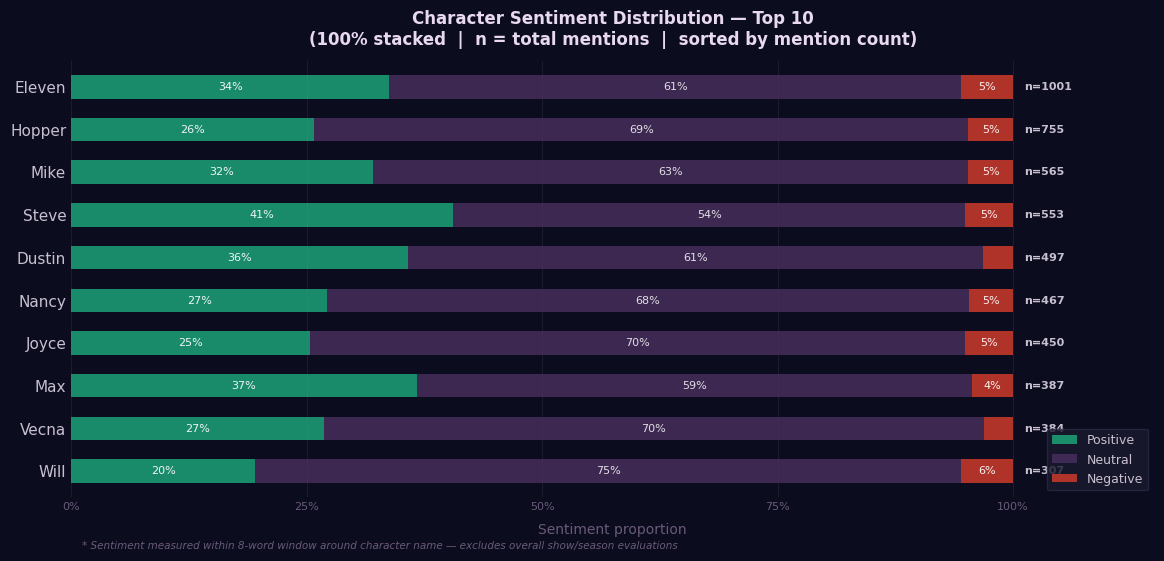

saved: char_stacked_v2.png


In [9]:
BG            = '#0B0C1E'
CARD          = '#1A1A2E'
GRID          = '#1E1A30'
TEXT          = '#C8C0D0'
MUTED         = '#6A5A7A'
GREEN         = '#1D9E75'
RED           = '#C8392B'
NEUTRAL_COLOR = '#4A3060'

top10    = char_stats.head(10)
chars    = top10.index.tolist()
pos_vals = top10['positive_rate'].tolist()
neu_vals = top10['neutral_rate'].tolist()
neg_vals = top10['negative_rate'].tolist()
mentions = top10['mentions'].tolist()

y     = np.arange(len(chars))
bar_h = 0.55

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

ax.barh(y, pos_vals, bar_h, color=GREEN,
        alpha=0.88, label='Positive', zorder=3)
ax.barh(y, neu_vals, bar_h, left=pos_vals,
        color=NEUTRAL_COLOR, alpha=0.78, label='Neutral', zorder=3)
ax.barh(y, neg_vals, bar_h,
        left=[p + n for p, n in zip(pos_vals, neu_vals)],
        color=RED, alpha=0.88, label='Negative', zorder=3)

# 右侧：提及次数
for i, (total, count) in enumerate(zip(
        [p + n + g for p, n, g in zip(pos_vals, neu_vals, neg_vals)], mentions)):
    ax.text(total + 1.2, i, f'n={count}',
            va='center', fontsize=8, color=TEXT,
            fontweight='bold', zorder=5)

# 绿色段：正面率
for i, p in enumerate(pos_vals):
    if p > 8:
        ax.text(p / 2, i, f'{p:.0f}%',
                ha='center', va='center',
                fontsize=8, color='white', alpha=0.92, zorder=5)

# 紫色段：中性率  ← 修正：之前这段缺失
for i, (p, n) in enumerate(zip(pos_vals, neu_vals)):
    if n > 8:
        ax.text(p + n / 2, i, f'{n:.0f}%',
                ha='center', va='center',
                fontsize=8, color='white', alpha=0.85, zorder=5)

# 红色段：负面率
for i, (p, n, g) in enumerate(zip(pos_vals, neu_vals, neg_vals)):
    if g > 4:
        ax.text(p + n + g / 2, i, f'{g:.0f}%',
                ha='center', va='center',
                fontsize=8, color='white', alpha=0.92, zorder=5)

ax.set_xlim(0, 115)
ax.set_ylim(-0.6, len(chars) - 0.4)
ax.set_yticks(y)
ax.set_yticklabels(chars, fontsize=11, color=TEXT)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(['0%', '25%', '50%', '75%', '100%'], fontsize=8, color=MUTED)
ax.set_xlabel('Sentiment proportion', fontsize=10, color=MUTED, labelpad=8)
ax.invert_yaxis()
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(length=0)
ax.xaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.legend(loc='lower right', facecolor=CARD, edgecolor='#2A2A45',
          labelcolor=TEXT, fontsize=9)

ax.text(0.01, -0.12,
        '* Sentiment measured within 8-word window around character name — '
        'excludes overall show/season evaluations',
        transform=ax.transAxes, fontsize=7.5,
        color=MUTED, style='italic')

ax.set_title(
    'Character Sentiment Distribution — Top 10\n'
    '(100% stacked  |  n = total mentions  |  sorted by mention count)',
    fontsize=12, color='#E8D8F0', pad=12, fontweight='bold'
)
plt.tight_layout(pad=2)
plt.savefig(PATH + 'char_stacked_v2.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('saved: char_stacked_v2.png')

## 图2：角色情感气泡图
X = 提及频次 | Y = 角色直接情感得分 | 气泡大小 = 正面率

右上角 = 高频 + 高正面 = 最佳品牌合作候选

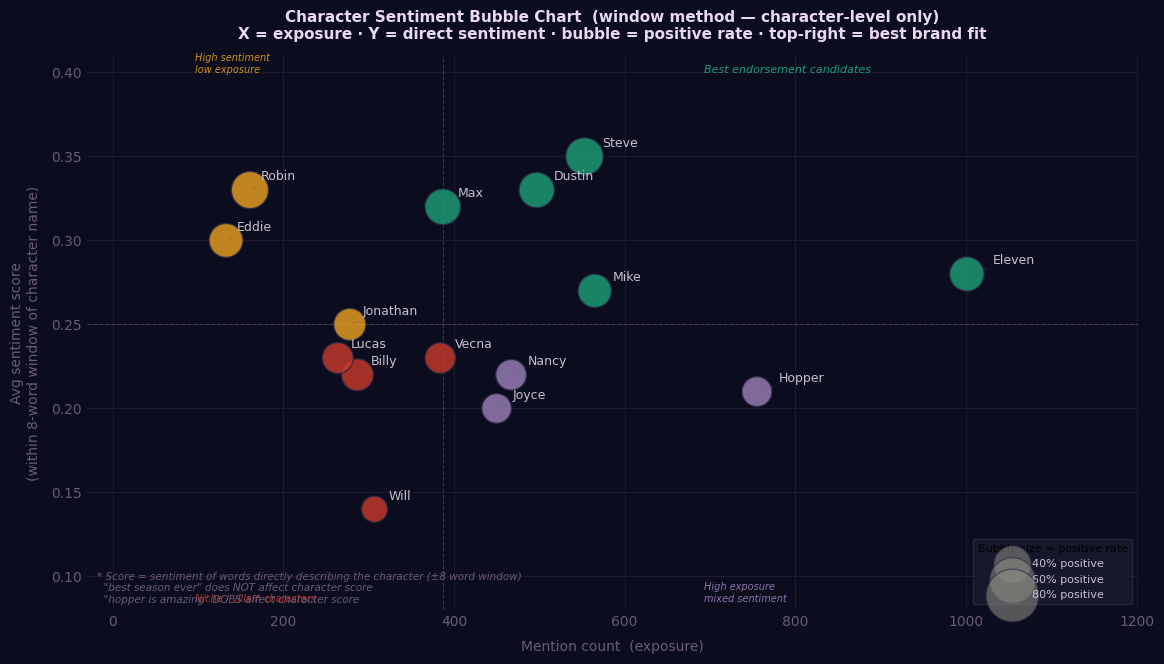

saved: char_bubble_v2.png


In [10]:
PURPLE     = '#9B7FB8'
AMBER      = '#E8A020'
all_chars  = char_stats.copy()
men        = all_chars['mentions'].tolist()
avg_sent   = all_chars['avg_sentiment'].tolist()
pos_rates  = all_chars['positive_rate'].tolist()
char_names = all_chars.index.tolist()

sizes      = [p * 18 for p in pos_rates]

med_x = np.median(men)
med_y = np.median(avg_sent)

# ── 按象限着色：右上=绿，左上=黄，右下=紫，左下=红 ──────────
def quadrant_color(x, y, mx, my):
    if x >= mx and y >= my:   return GREEN    # 右上：最佳候选 → 绿
    elif x < mx and y >= my:  return AMBER    # 左上：高情感低曝光 → 黄
    elif x >= mx and y < my:  return PURPLE   # 右下：高曝光有争议 → 紫
    else:                     return RED      # 左下：小众/反派 → 红

colors_sc  = [
    quadrant_color(men[i], avg_sent[i], med_x, med_y)
    for i in range(len(men))
]

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

ax.scatter(men, avg_sent, s=sizes, c=colors_sc,
           alpha=0.82, edgecolors='#2A2A45',
           linewidths=1.0, zorder=4)

for i, name in enumerate(char_names):
    ax.annotate(
        name,
        (men[i], avg_sent[i]),
        xytext=(men[i] + men[i] * 0.02 + 10, avg_sent[i] + 0.006),
        fontsize=9, color=TEXT, zorder=5,
        arrowprops=dict(arrowstyle='-', color=MUTED,
                        lw=0.5, alpha=0.5)
    )

ax.axvline(x=med_x, color=MUTED, linewidth=0.8,
           linestyle='--', alpha=0.5)
ax.axhline(y=med_y, color=MUTED, linewidth=0.8,
           linestyle='--', alpha=0.5)

x_max = max(men) * 1.15
y_max = max(avg_sent) + 0.06
y_min = min(avg_sent) - 0.06

ax.text(med_x + (x_max - med_x) * 0.4, y_max - 0.01,
        'Best endorsement candidates',
        fontsize=8, color=GREEN, style='italic')
ax.text(med_x - med_x * 0.75, y_max - 0.01,
        'High sentiment\nlow exposure',
        fontsize=7, color=AMBER, style='italic', alpha=0.9)
ax.text(med_x + (x_max - med_x) * 0.4, y_min + 0.005,
        'High exposure\nmixed sentiment',
        fontsize=7, color=PURPLE, style='italic', alpha=0.9)
ax.text(med_x - med_x * 0.75, y_min + 0.005,
        'Niche / villain characters',
        fontsize=7, color=RED, style='italic', alpha=0.9)

ax.set_xlabel('Mention count  (exposure)',
              fontsize=10, color=MUTED, labelpad=8)
ax.set_ylabel('Avg sentiment score\n(within 8-word window of character name)',
              fontsize=10, color=MUTED, labelpad=8)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
ax.xaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.yaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.set_xlim(-30, max(men) * 1.2)
ax.set_ylim(y_min, y_max)

for label, rate in [
    ('40% positive', 40 * 18),
    ('60% positive', 60 * 18),
    ('80% positive', 80 * 18)
]:
    ax.scatter([], [], s=rate, c='#888780',
               alpha=0.6, edgecolors='#2A2A45', label=label)
ax.legend(
    title='Bubble size = positive rate',
    title_fontsize=8,
    facecolor=CARD, edgecolor='#2A2A45',
    labelcolor=TEXT, fontsize=8, loc='lower right'
)

ax.text(0.01, 0.01,
        '* Score = sentiment of words directly describing the character (±8 word window)\n'
        '  "best season ever" does NOT affect character score\n'
        '  "hopper is amazing" DOES affect character score',
        transform=ax.transAxes, fontsize=7.5,
        color=MUTED, style='italic', va='bottom')

ax.set_title(
    'Character Sentiment Bubble Chart  (window method — character-level only)\n'
    'X = exposure · Y = direct sentiment · bubble = positive rate · '
    'top-right = best brand fit',
    fontsize=11, color='#E8D8F0', pad=12, fontweight='bold'
)
plt.tight_layout(pad=2)
plt.savefig(PATH + 'char_bubble_v2.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('saved: char_bubble_v2.png')